# 01 — La serie de triage: qué mide y qué no

## Qué contesta este cuadernoAntes de preguntarse si el clima mueve las consultas, hay que saber cómo se comporta laserie **sola**. 

Ese es todo el objetivo aquí. Cinco preguntas, en orden:

1. **¿Cuánta gente viene, y va a más o a menos?**

2. **¿Cuándo vienen?** — la hora, el día de la semana, el mes.

3. **¿Qué tipo de hospital es este?** — qué fracción es urgencia real.

4. **¿La caída de los últimos dos años es real?**

5. **¿Cuánto tarda la atención, y sirve como medida de saturación?**

## Cómo leerloCada figura va seguida de su lectura y de **sus límites**. 

Una figura sin eso al lado no esun resultado: es un dibujo. Donde un número contradice algo que se creía antes, se dice.

## De dónde salen los datosDe `salidas/*.parquet`, que son agregados ya extraídos. 

**Este cuaderno no se conecta aSQL Server**: corre entero sin acceso a la historia clínica, que es lo que permite que otrapersona reproduzca las figuras. Los agregados se regeneran con `python -m extraccion --series`.

In [ ]:
import sys, pathlib
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from clustering.visualizaciones import datos, figuras

total    = datos.marco(datos.total())                                  # dia x hora
nivel    = pd.read_parquet(RAIZ / "salidas" / "triage_nivel.parquet")  # dia x hora x nivel
edad     = pd.read_parquet(RAIZ / "salidas" / "triage_edad.parquet")   # dia x banda
estancia = pd.read_parquet(RAIZ / "salidas" / "triage_estancia.parquet")

serie = datos.serie_diaria(total)
print(f"{total['n'].sum():,} triages   {total['dia'].nunique():,} dias   "
      f"{serie.index.min():%Y-%m-%d} a {serie.index.max():%Y-%m-%d}")

433,392 triages   2,454 dias   2020-01-01 a 2026-09-21


---# 1. El volumen — y la primera corrección## 1.1 Media diaria por mes y año

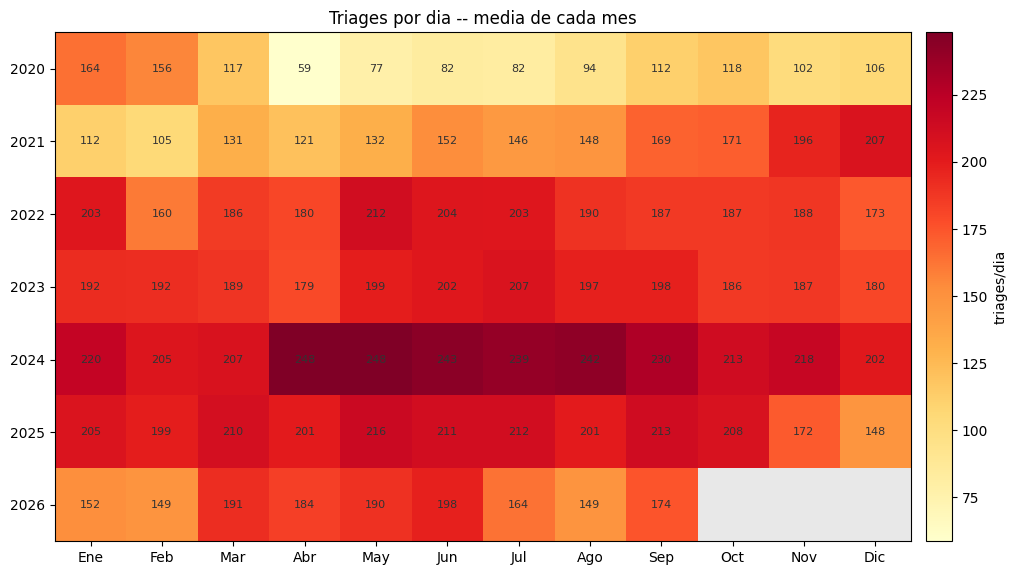

Media diaria por anio:
  2020    105.7
  2021    149.3
  2022    189.6
  2023    192.4
  2024    226.4
  2025    199.6
  2026    172.3

Pico: 2024 con 226.4
2026: 172.3  ->  -23.9% desde el pico


In [ ]:
fig = figuras.mes_anio(serie, titulo="Triages por dia -- media de cada mes")
plt.show()

anual = serie.groupby(serie.index.year).mean()
print("Media diaria por anio:")
for a, v in anual.items():
    print(f"  {a}   {v:6.1f}")
print(f"\nPico: {anual.idxmax()} con {anual.max():.1f}")
print(f"2026: {anual.loc[2026]:.1f}  ->  {100*(anual.loc[2026]/anual.max()-1):+.1f}% desde el pico")

## Lectura**La serie no crece. Subió hasta 2024 y lleva dos años cayendo.**| 2020 | 2021 | 2022 | 2023 | **2024** | 2025 | 2026 ||---|---|---|---|---|---|---|| 105,7 | 149,3 | 189,6 | 192,4 | **226,4** | 199,6 | 172,3 |Desde el pico de 2024 la caída acumulada es del **23,9 %**.> **Esto corrige una conclusión anterior.** En `exploracion.ipynb` se escribió que había> «un aumento progresivo a lo largo de los años, siendo cada vez mayor la cantidad». Era> una lectura hecha deprisa sobre el calendario; con los siete años medidos no se sostiene.**El 2020 es un cráter de COVID, no un año flojo**: de 164 triages/día en enero a **59 enabril**, un −64 %. Consecuencia práctica: 2020 no entra en ningún entrenamiento sintratarlo aparte, porque le enseña al modelo una forma anual que no es la del hospital.**La estacionalidad anual, excluyendo 2020, es del 19,7 %** — pico en junio (202triages/día), valle en febrero (169). Existe y es modesta. La «campana con pico en junio yjulio» que se describió antes venía sobre todo de que el cráter de 2020 hundía el mediodíadel año.### LímitesLa caída del 23,9 % se explica **en parte** por un cambio de criterio de clasificación, nosolo por menos demanda. Eso se demuestra en la sección 4, y hay que leer esta cifra conesa advertencia delante.

## 1.2 El día a día

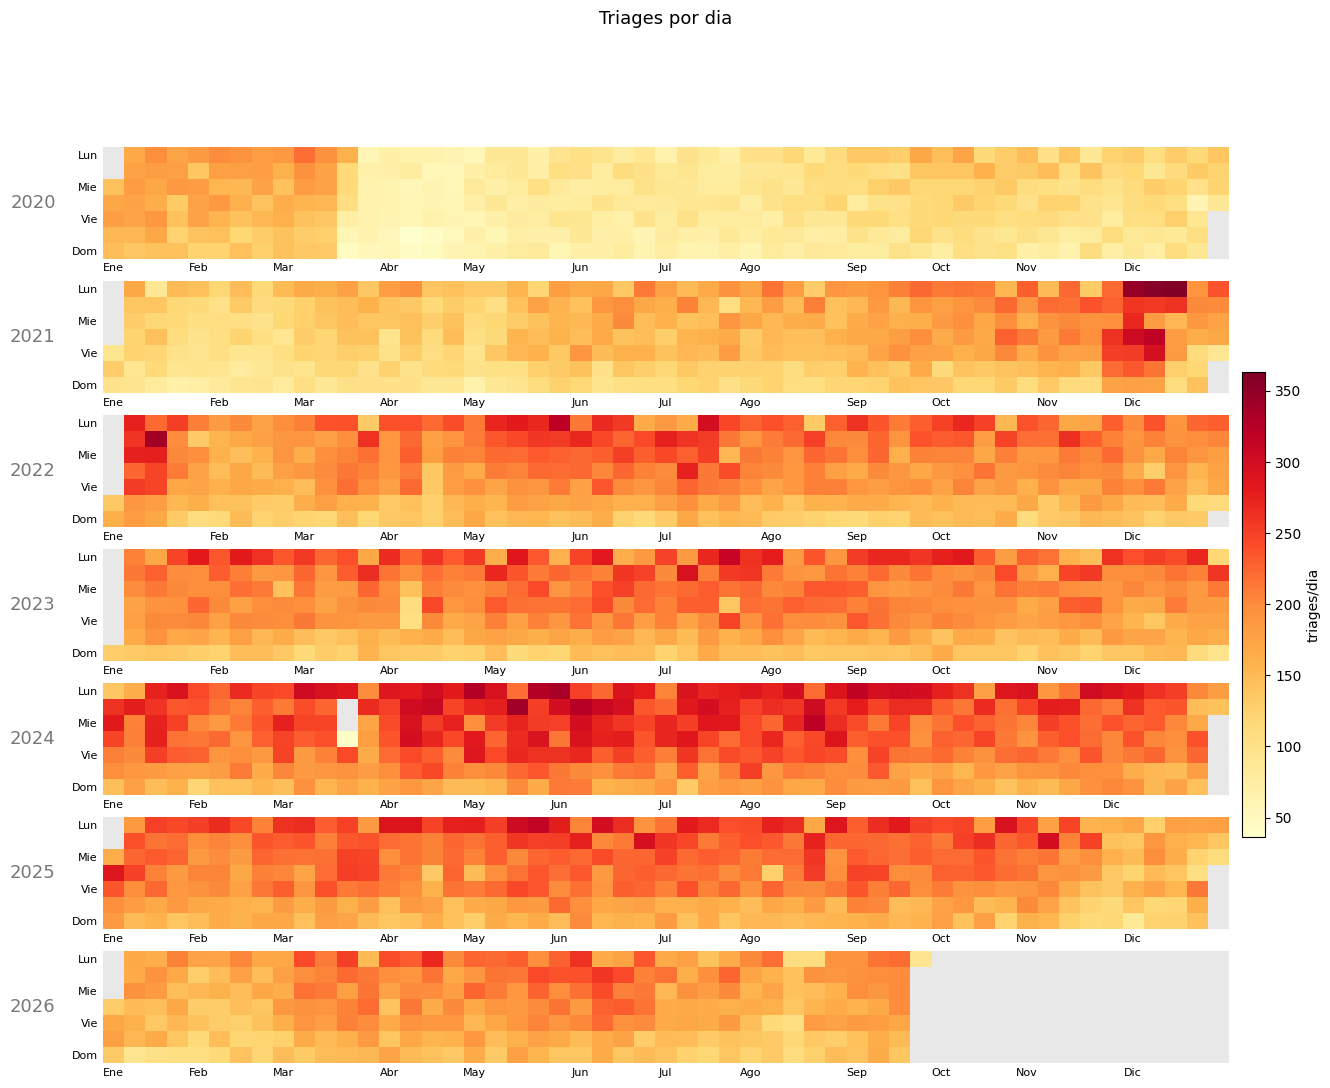

In [ ]:
fig = figuras.calendario(serie, titulo="Triages por dia", etiqueta="triages/dia")
plt.show()

## LecturaEl calendario muestra tres cosas que la media anual esconde:- **El bloque claro de 2020**, de marzo a julio, es el confinamiento.- **La trama vertical constante**: son los domingos. El ciclo semanal es tan regular que se  ve a simple vista en los siete años.- **El apagado progresivo de 2025-2026**, que no es un escalón sino un desvanecimiento.Ningún día aparece en gris: **no hay huecos de registro** en los 2.454 días.

---# 2. El ritmo — la hora manda sobre el día de la semana## 2.1 Hora × día de la semana

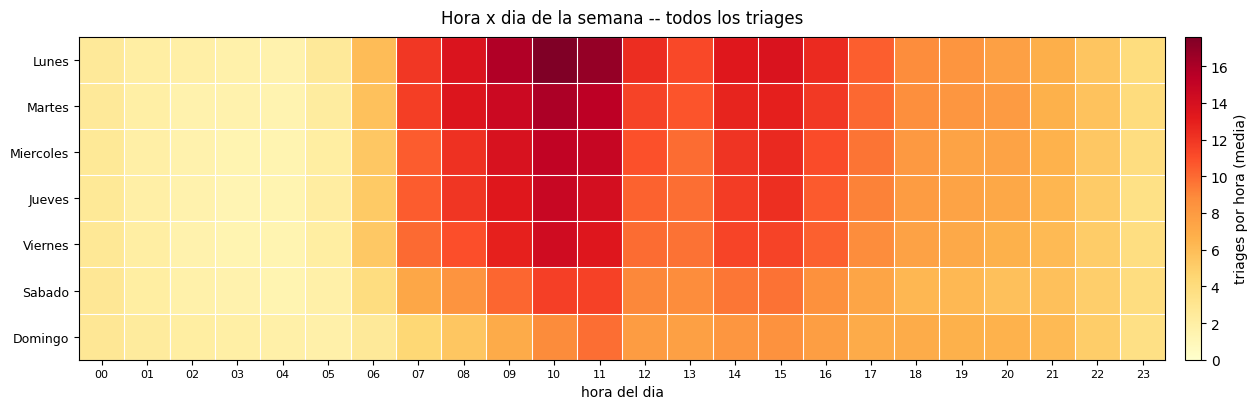

pico  Lunes 10h -> 17.6 triages/h
valle Jueves 03h -> 1.3 triages/h
oscilacion hora x dia : 13.9x
oscilacion semanal    : 1.57x  (Lunes 208.5 -> Domingo 132.7)


In [ ]:
fig = figuras.reloj_semanal(total)
plt.show()

nd = total.drop_duplicates("dia").groupby("dow")["dia"].nunique()
med = total.pivot_table(index="dow", columns="hora", values="n", aggfunc="sum").div(nd, axis=0)
i = np.unravel_index(np.nanargmax(med.to_numpy()), med.shape)
j = np.unravel_index(np.nanargmin(med.to_numpy()), med.shape)
print(f"pico  {datos.DIAS[med.index[i[0]]]} {med.columns[i[1]]:02d}h -> {med.to_numpy()[i]:.1f} triages/h")
print(f"valle {datos.DIAS[med.index[j[0]]]} {med.columns[j[1]]:02d}h -> {med.to_numpy()[j]:.1f} triages/h")
print(f"oscilacion hora x dia : {med.to_numpy()[i]/med.to_numpy()[j]:.1f}x")

pd_ = serie.groupby(serie.index.dayofweek).mean()
print(f"oscilacion semanal    : {pd_.max()/pd_.min():.2f}x  "
      f"({datos.DIAS[pd_.idxmax()]} {pd_.max():.1f} -> {datos.DIAS[pd_.idxmin()]} {pd_.min():.1f})")

## Lectura**El pico es el lunes a las 10 con 17,6 triages/hora. El valle es el jueves a las 3 con1,3. Eso es 13,9× de oscilación** — contra 1,57× entre lunes y domingo.> **La hora es casi nueve veces más informativa que el día de la semana**, y hasta este> cuaderno no había ninguna figura que lo mostrara.Tiene una consecuencia directa de diseño: cualquier control de calendario que use solo eldía de la semana está dejando fuera la variable que más manda.

## 2.2 La forma del día

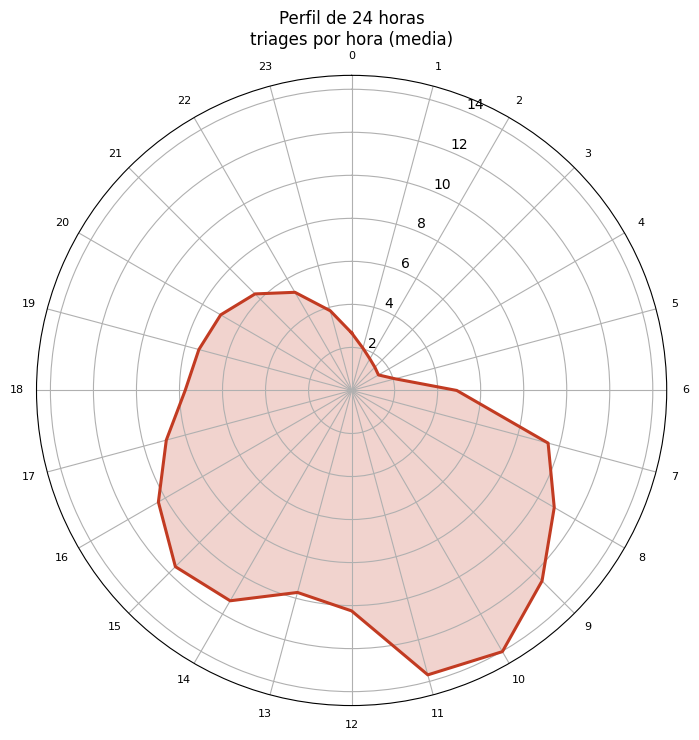

Cuota de la madrugada (00-05h) dentro del dia:
  Lunes       5.86%
  Martes      5.64%
  Miercoles   5.80%
  Jueves      5.94%
  Viernes     6.30%
  Sabado      7.52%
  Domingo     9.61%

domingo / jueves = 1.62x   (sin interaccion seria 1,00)
varianza que explica el modelo aditivo (dia + hora): 97.30%
residuo maximo: 1.69x


In [ ]:
fig = figuras.polar(total)
plt.show()

forma = med.div(med.sum(axis=1), axis=0)
mad = forma.loc[:, 0:5].sum(axis=1)
print("Cuota de la madrugada (00-05h) dentro del dia:")
for d in range(7):
    print(f"  {datos.DIAS[d]:<10} {100*mad[d]:5.2f}%")
print(f"\ndomingo / jueves = {mad[6]/mad[3]:.2f}x   (sin interaccion seria 1,00)")

L = np.log(med.to_numpy())
aditivo = L.mean() + (L.mean(axis=1) - L.mean())[:, None] + (L.mean(axis=0) - L.mean())[None, :]
resid = L - aditivo
print(f"varianza que explica el modelo aditivo (dia + hora): {100*(1-resid.var()/L.var()):.2f}%")
print(f"residuo maximo: {np.exp(np.abs(resid).max()):.2f}x")

## Lectura**El día tiene dos jorobas**, no una: pico a las 10-11, **valle a las 13-14**, segundo picoa las 18-19, colapso entre las 2 y las 5.Eso no es un detalle estético. Si el ciclo diario se modela con ondas (Fourier), **un soloarmónico de 24 h dibuja una sola joroba**. Harán falta dos o tres. Ahora se sabe por qué, yno por tanteo.**Y hay interacción entre la hora y el día de la semana.** El modelo aditivo explica el97,30 % de la rejilla — casi todo — pero el residuo máximo es 1,69× y no está repartido alazar:| | Cuota de la madrugada ||---|---|| Jueves | 5,94 % || Sábado | 7,52 % || **Domingo** | **9,61 %** |**Domingo / jueves = 1,62×.** El fin de semana no solo tiene menos volumen: **tiene otraforma**.Es la primera señal, sin haber clasificado una sola nota, de que **lo que se consultacambia con el momento**. Una mañana de lunes y una madrugada de domingo no traen a la mismagente. La sección 3 lo confirma por otra vía.

---# 3. Qué tipo de hospital es esteEl nivel de urgencia (`HCNCLAURGTR`) está **al 100 % en los 433.620 registros desde 2020**.No depende del texto ni de ningún modelo: es una clasificación que hace el personal en elmomento del triage.

In [ ]:
resumen = (nivel.groupby(["nivel", "nivel_nombre"])["n"].sum()
           .sort_values(ascending=False).reset_index())
resumen["cuota"] = 100 * resumen["n"] / resumen["n"].sum()
print(f"{'nivel':<8}{'descripcion':<42}{'n':>10}{'cuota':>8}")
for _, r in resumen.head(10).iterrows():
    print(f"{r.nivel:<8}{str(r.nivel_nombre)[:40]:<42}{r.n:>10,}{r.cuota:>7.1f}%")

GRUPO = {"I": "urgente", "II": "urgente", "I-G": "urgente", "II-G": "urgente",
         "IIIU": "urgencia", "III": "diferido", "III-G": "diferido",
         "IV": "no urgente", "IV-G": "no urgente",
         "V": "consulta externa", "V-G": "consulta externa"}
nivel["grupo"] = nivel["nivel"].map(GRUPO).fillna("otro")
g = nivel.groupby("grupo")["n"].sum()
g = 100 * g / g.sum()
print(f"\n  urgencia real (I, II)     {g.get('urgente', 0):5.1f}%")
print(f"  urgencia (IIIU)           {g.get('urgencia', 0):5.1f}%")
print(f"  diferido (III)            {g.get('diferido', 0):5.1f}%")
print(f"  NO urgente (IV) + externa {g.get('no urgente', 0) + g.get('consulta externa', 0):5.1f}%")

nivel   descripcion                                        n   cuota
IV      DIFERIDA/NO URGENTE                          169,764   39.2%
IIIU    URGENCIA                                     106,626   24.6%
V       CONSULTA EXTERNA                              53,014   12.2%
III-G   URGENCIA OBSTETRICA DIFERIDA O MENOR          47,330   10.9%
III     DIFERIDA                                      41,781    9.6%
II      URGENCIA MEDICA                                6,479    1.5%
II-G    URGENCIA MEDICA OBSTETRICA                     6,302    1.5%
I       EMERGENCIA                                     1,463    0.3%
M       MUERTO                                           285    0.1%
IV-G    NO URGENTE OBSTETRICA                            266    0.1%



  urgencia real (I, II)       3.3%
  urgencia (IIIU)            24.6%
  diferido (III)             20.6%
  NO urgente (IV) + externa  51.5%


## Lectura| Nivel | Qué es | Cuota ||---|---|---|| IV | Diferida / no urgente | **39,2 %** || IIIU | Urgencia | 24,6 % || V | Consulta externa | 12,2 % || III-G | Urgencia obstétrica diferida | 10,9 % || III | Diferida | 9,6 % || II + II-G | Urgencia médica | 3,0 % || **I + I-G** | **Emergencia** | **0,4 %** |> **Más de la mitad de los triages de este hospital son no urgentes (IV + V = 51,4 %).> Las emergencias reales son el 0,4 %: 1.463 casos en seis años y medio.**Esto contesta la pregunta de qué tipo de servicio es, y **sostiene el mecanismo que elproyecto quiere medir**. La hipótesis de partida era:> *«a la gente le empieza a dar gripa, y las personas con gripa van al hospital, o por lo> menos a que les generen la incapacidad del día por el triage»*Un servicio donde la mitad de las consultas son no urgentes es exactamente donde esecomportamiento es posible. Si el 90 % fueran emergencias, la hipótesis sería poco creíble.**Hay además un componente obstétrico grande**: los niveles con sufijo `-G` suman un12,6 %. Esa población no responde al clima igual que el resto, y conviene poder separarla.### LímitesEl nivel lo asigna una persona con un criterio, y **ese criterio cambió**. Es la secciónsiguiente, y obliga a releer todo lo anterior.

---# 4. La caída no es lo que pareceLa sección 1 dejó abierta la pregunta: **¿por qué cayó el volumen un 23,9 % desde 2024?**Si la caída fuera de demanda, debería repartirse por igual entre los niveles de urgencia.Si fuera de clasificación, se concentraría.

In [ ]:
anual = nivel.assign(anio=nivel["dia"].dt.year).pivot_table(
    index="anio", columns="grupo", values="n", aggfunc="sum").fillna(0)
orden = ["urgente", "urgencia", "diferido", "no urgente", "consulta externa"]
anual = anual[[c for c in orden if c in anual.columns]]

print("CUOTA POR ANIO (%)")
print((100 * anual.div(anual.sum(axis=1), axis=0)).round(1).to_string())

print("\nCAMBIO 2024 -> 2026 (2026 anualizado)")
a, b = anual.loc[2024], anual.loc[2026] * 365 / 264
for c in anual.columns:
    print(f"  {c:<18}{a[c]:>9,.0f} ->{b[c]:>9,.0f}   {100*(b[c]/a[c]-1):+7.1f}%")
print(f"  {'TOTAL':<18}{a.sum():>9,.0f} ->{b.sum():>9,.0f}   {100*(b.sum()/a.sum()-1):+7.1f}%")

CUOTA POR ANIO (%)
grupo  urgente  urgencia  diferido  no urgente  consulta externa
anio                                                            
2020       5.9      34.9      23.6        19.4              16.2
2021       3.9      29.0      20.9        35.2              10.9
2022       3.1      24.4      14.8        45.5              12.2
2023       2.3      25.4      15.4        46.5              10.4
2024       1.9      21.2      14.3        48.4              14.1
2025       3.3      21.5      25.4        37.2              12.6
2026       4.8      20.9      37.7        26.9               9.7

CAMBIO 2024 -> 2026 (2026 anualizado)
  urgente               1,600 ->    3,024     +89.0%
  urgencia             17,453 ->   13,198     -24.4%
  diferido             11,816 ->   23,811    +101.5%
  no urgente           39,879 ->   16,997     -57.4%
  consulta externa     11,600 ->    6,139     -47.1%
  TOTAL                82,348 ->   63,169     -23.3%


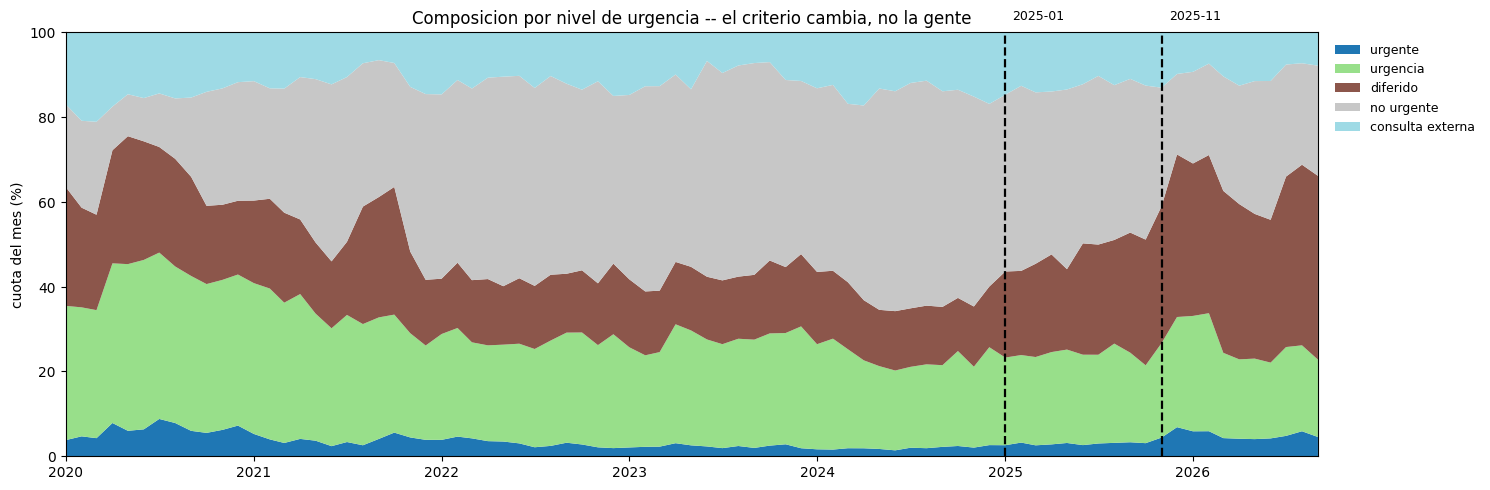

In [ ]:
mensual = nivel.assign(ym=nivel["dia"].dt.to_period("M")).pivot_table(
    index="ym", columns="grupo", values="n", aggfunc="sum").fillna(0)
mensual = mensual[[c for c in orden if c in mensual.columns]]
cuota = 100 * mensual.div(mensual.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 5))
ax.stackplot(cuota.index.to_timestamp(), cuota.to_numpy().T, labels=cuota.columns,
             colors=plt.get_cmap("tab20")(np.linspace(0, 1, cuota.shape[1])))
ax.axvline(pd.Timestamp("2025-01-01"), color="black", lw=1.6, ls="--")
ax.axvline(pd.Timestamp("2025-11-01"), color="black", lw=1.6, ls="--")
ax.text(pd.Timestamp("2025-01-15"), 103, "2025-01", fontsize=9)
ax.text(pd.Timestamp("2025-11-15"), 103, "2025-11", fontsize=9)
ax.set_ylim(0, 100); ax.set_xlim(cuota.index.to_timestamp().min(), cuota.index.to_timestamp().max())
ax.set_ylabel("cuota del mes (%)")
ax.set_title("Composicion por nivel de urgencia -- el criterio cambia, no la gente", fontsize=12)
ax.legend(loc="upper left", bbox_to_anchor=(1.005, 1), fontsize=9, frameon=False)
plt.tight_layout(); plt.show()

## Lectura — este es el hallazgo principal del cuaderno**La caída no se reparte. Se concentra, y en direcciones opuestas.**| Grupo | 2024 → 2026 ||---|---|| Diferido (III) | **+101,5 %** || Urgente (I, II) | **+89,0 %** || Urgencia (IIIU) | −24,4 % || **No urgente (IV)** | **−57,4 %** || Consulta externa (V) | −47,1 % || **TOTAL** | **−23,3 %** |La cuota de «no urgente» pasó del **48,4 % en 2024 al 26,9 % en 2026**, mientras «diferido»subía del 14,3 % al 37,7 %. Y «urgente» se duplicó.> **Las emergencias reales no se duplican en dos años. Lo que cambió es dónde se pone la> raya.** Es una deriva del criterio de triage, no un cambio en quién llega.**Cuándo pasó**: no es un escalón, es una deriva progresiva que arranca en **enero de 2025**y se acelera en **noviembre-diciembre de 2025**, donde además cae el volumen total de golpe(6.431 → 5.161 → 4.572 triages/mes).## Cuatro consecuencias, y ninguna es menor1. **La caída del 23,9 % es en parte artefacto.** Hay menos demanda real, pero mucho menos   del 23,9 %. Un modelo entrenado sobre el total 2024-2026 está modelando un cambio de   criterio administrativo.2. **El nivel de urgencia no es comparable a lo largo del tiempo.** Sirve para caracterizar   el hospital (sección 3) y para separar poblaciones dentro de un periodo corto, pero un   «triage IV» de 2024 y uno de 2026 no son lo mismo.3. **La ventana con texto es justo la ventana contaminada.** `HCTMOTCON` existe desde 2025,   que es exactamente cuando empieza la deriva. Cualquier serie por motivo cae encima de   este cambio.4. **Hay que auditar el resto de variables igual.** Si una columna central tiene una deriva   no documentada, no hay razón para suponer que las demás no la tengan. La sección 5   encuentra la segunda.

---# 5. La estancia — y tres regímenes de medición`HCCFECSAL − HCCFECTUR` da el tiempo que pasa entre que el paciente entra al servicio ysale. La cobertura es del **91,1 %** y —a diferencia del texto— **es estable en los sieteaños** (85-94 %), así que no mete tendencia falsa por sí misma.Es la variable que más se acerca a la pregunta operativa real: *¿hace falta más personal?*Un pico de consultas que el servicio absorbe sin que suba la espera no es saturación; unoque la sube, sí.

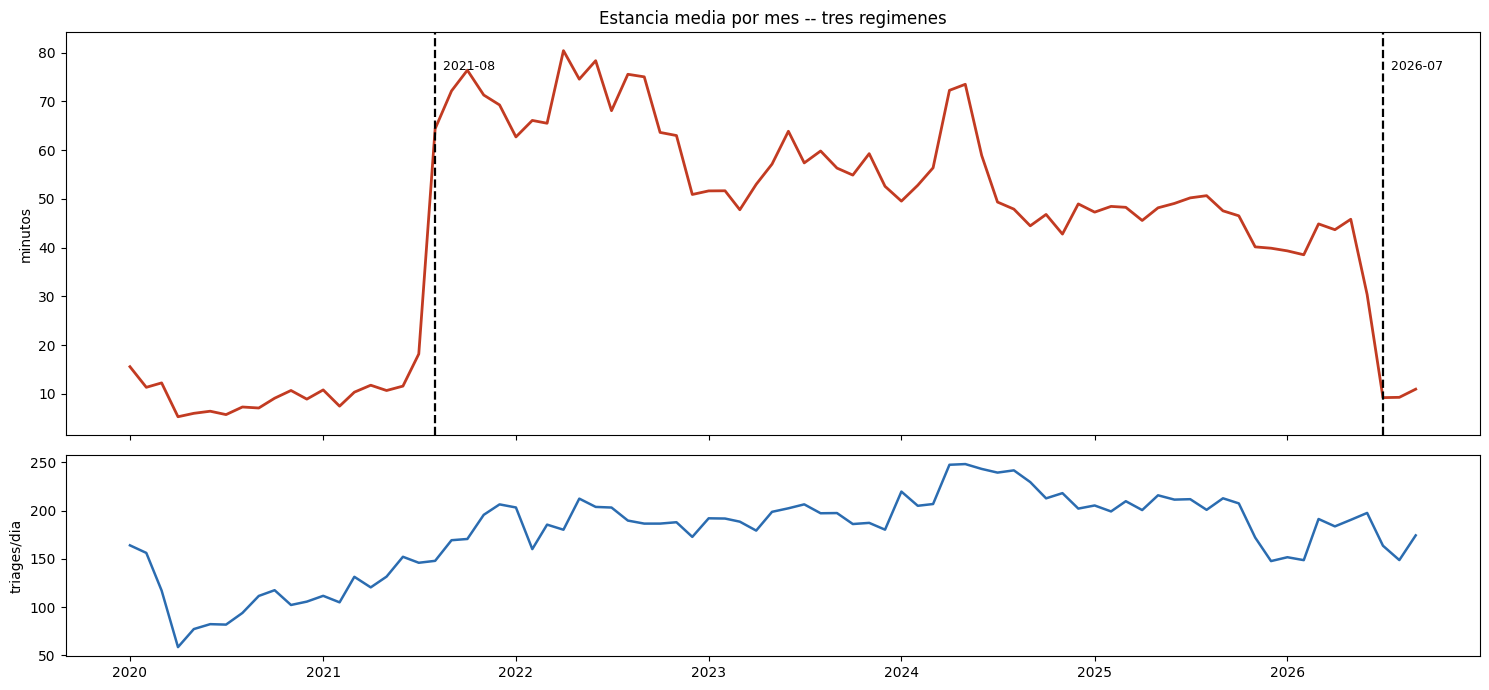

  regimen 1  2020-01 a 2021-07   estancia media   9.8 min
  regimen 2  2021-08 a 2026-06   estancia media  55.8 min
  regimen 3  2026-07 a 2026-09   estancia media   9.9 min


In [ ]:
est = estancia.set_index("dia").sort_index()
mens = est.resample("MS").apply(lambda d: np.average(d["media_min"], weights=d["n"])
                                if len(d) else np.nan)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(mens.index, mens.to_numpy(), lw=2, color="#c23b22")
for corte, nota in [("2021-08-01", "2021-08"), ("2026-07-01", "2026-07")]:
    ax1.axvline(pd.Timestamp(corte), color="black", lw=1.6, ls="--")
    ax1.text(pd.Timestamp(corte), mens.max() * 0.95, f"  {nota}", fontsize=9)
ax1.set_ylabel("minutos"); ax1.set_title("Estancia media por mes -- tres regimenes", fontsize=12)

vol = serie.resample("MS").mean()
ax2.plot(vol.index, vol.to_numpy(), lw=1.8, color="#2b6cb0")
ax2.set_ylabel("triages/dia"); ax2.set_xlabel("")
plt.tight_layout(); plt.show()

for desde, hasta, nombre in [("2020-01", "2021-07", "regimen 1"),
                             ("2021-08", "2026-06", "regimen 2"),
                             ("2026-07", "2026-09", "regimen 3")]:
    v = mens.loc[desde:hasta]
    print(f"  {nombre}  {desde} a {hasta}   estancia media {v.mean():5.1f} min")

## Lectura**La estancia tiene dos saltos bruscos, y ninguno es clínico.**| Régimen | Periodo | Estancia media | Mediana ||---|---|---|---|| 1 | 2020-01 → 2021-07 | **9,8 min** | 3-10 min || 2 | 2021-08 → 2026-06 | **55,8 min** | 28-60 min || 3 | 2026-07 → 2026-09 | **9,9 min** | 5-6 min |Entre julio y agosto de 2021 la mediana salta de 9 a 39 minutos — **4,3× en un mes**. Yentre junio y julio de 2026 se desploma de 21 a 5.> **Un servicio de urgencias no cuadruplica su tiempo de atención en un mes, ni lo divide> por cuatro al mes siguiente. Lo que cambió es qué se graba en `HCCFECSAL`.**## Qué queda de esto- **La variable sirve, pero solo dentro del régimen 2**: agosto 2021 a junio 2026, que son  casi cinco años y 300.000 registros. Es ventana de sobra.- **Las comparaciones entre regímenes no valen.** La media anual de la sección anterior  (9,8 min en 2020 frente a 69,5 en 2022) no mide nada real.- **Segunda deriva no documentada encontrada en el mismo cuaderno.** Ya son dos: el criterio  de triage y el registro de salida. Esto deja de ser una anécdota y pasa a ser un método:  **antes de usar cualquier columna, hay que mirar su serie mensual buscando escalones.**

---# Conclusiones## Lo que ahora se sabe1. **La serie no crece: cayó un 23,9 % desde el pico de 2024** — pero buena parte de esa   caída es reclasificación, no menos gente.2. **2020 es un cráter de COVID** (−64 % entre enero y abril) y no entra en ningún   entrenamiento sin tratarlo aparte.3. **La hora manda: 13,9× de oscilación contra 1,57× del día de la semana.**4. **El día tiene dos jorobas.** Un solo armónico de 24 h no lo describe.5. **Hay interacción hora × día**: la madrugada pesa 1,62× más el domingo que el jueves. El   fin de semana tiene otra *forma*, no solo menos volumen.6. **Más de la mitad del hospital es no urgente** (51,4 %), y las emergencias son el 0,4 %.   Eso sostiene el mecanismo de la incapacidad que el proyecto quiere medir.7. **Dos derivas de medición no documentadas**: el criterio de triage desde enero de 2025 y   el registro de salida en agosto de 2021 y julio de 2026.## Lo que este cuaderno cambia en el plan- **El control de calendario necesita la hora**, y con dos o tres armónicos, no uno.- **La ventana de modelado útil no son los siete años.** Hay que elegirla a conciencia:  2022-2024 es el tramo más limpio para el total; agosto 2021 - junio 2026 para la estancia.- **Auditar antes de usar** pasa a ser un paso obligatorio de cualquier variable nueva.- **La ventana con texto (2025-2026) coincide con la deriva del criterio.** Cualquier serie  por motivo hereda ese problema y hay que tenerlo delante al interpretarla.## Lo que queda abierto- **¿Por qué cambió el criterio de triage en enero de 2025?** ¿Hubo una directriz, un cambio  de contrato, una auditoría? Es información que no está en la base.- **¿Qué pasó en noviembre de 2025?** Cae el volumen y se acelera la reclasificación a la  vez. Un solo evento explicaría las dos cosas.- **¿Qué significa `HCCFECSAL` en cada régimen?** Sin saberlo no se puede interpretar la  estancia ni siquiera dentro del régimen 2.- **La edad en bandas está extraída y sin mirar.** Es el siguiente cuaderno: la firma de una  epidemia respiratoria es un pico en 0-4 y en 65+ antes que en el resto.